# Fase 3 - Preparación de los datos

## 3.1 Limpieza y codificación del objetivo

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "bank-full.csv").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "Data" / "bank-full.csv"
MODELS_DIR = ROOT / "Modelos"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv(DATA_PATH, sep=";")
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicados eliminados:", antes - len(df))
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()
df["y"] = df["y"].map({"no": 0, "yes": 1}).astype("int8")
df["y"].value_counts()

Duplicados eliminados: 0


y
0    39922
1     5289
Name: count, dtype: int64

## 3.2 Selección de variables disponibles antes del contacto
Se excluyen `duration`, `campaign`, `day`, `month` y `contact` porque dependen del contacto actual y no están disponibles al priorizar clientes.

In [2]:
POST_CONTACT = ["duration", "campaign", "day", "month", "contact"]
X = df.drop(columns=["y"] + POST_CONTACT)
y = df["y"]
print("Predictores utilizados:", X.columns.tolist())

Predictores utilizados: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'pdays', 'previous', 'poutcome']


## 3.3 División Train / Validación / Test ciego (60 / 20 / 20, estratificada)

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42)
resumen = pd.DataFrame({
    "filas": [len(y_train), len(y_val), len(y_test)],
    "% yes": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Validacion", "Test ciego"]).round(2)
resumen

,filas,% yes
Train,27126,11.7
Validacion,9042,11.7
Test ciego,9043,11.7


## 3.4 Imputación, escalamiento y codificación One-Hot
Se definen dentro de un `ColumnTransformer` que se ajusta **solo con el entrenamiento** (dentro de cada pipeline y de cada fold), evitando fuga de información.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), num_cols),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])

preprocessor = make_preprocessor().fit(X_train)
print("Numericas:", num_cols)
print("Categoricas:", cat_cols)
print("Columnas tras la codificacion:", len(preprocessor.get_feature_names_out()))

Numericas: ['age', 'balance', 'pdays', 'previous']
Categoricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']
Columnas tras la codificacion: 33


## 3.5 Selección de variables (ranking por información mutua, solo con entrenamiento)

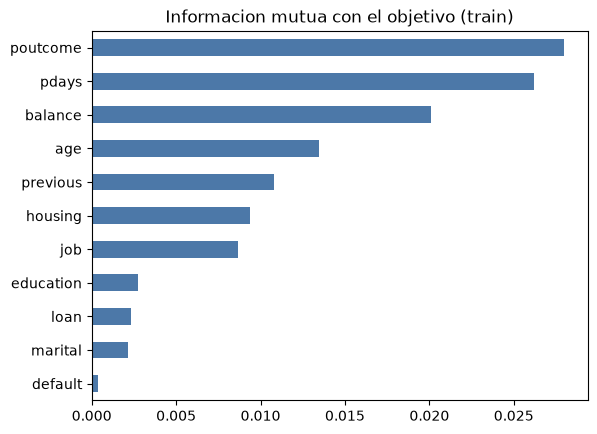

poutcome     0.0280
pdays        0.0262
balance      0.0201
age          0.0134
previous     0.0108
housing      0.0094
job          0.0087
education    0.0027
loan         0.0023
marital      0.0021
default      0.0004
dtype: float64

In [5]:
from sklearn.feature_selection import mutual_info_classif

enc = X_train.copy()
discretas = [not pd.api.types.is_numeric_dtype(enc[c]) for c in enc.columns]
for c in enc.columns:
    if not pd.api.types.is_numeric_dtype(enc[c]):
        enc[c] = enc[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(enc, y_train, discrete_features=discretas, random_state=42),
               index=X_train.columns).sort_values()
mi.plot(kind="barh", color="#4C78A8", title="Informacion mutua con el objetivo (train)")
plt.show()
mi.sort_values(ascending=False).round(4)

## 3.6 Hallazgos y decisiones
- Se mantienen 11 predictores previos al contacto; la partición estratificada conserva la proporción de `yes` (≈ 11,7 %) en los tres conjuntos.
- Los atípicos no se eliminan; se limitan por la estandarización y por modelos robustos (árboles).
- La Iteración 2 refina la selección con `SelectPercentile` sobre las columnas ya codificadas, dentro de cada fold de validación cruzada.
- El notebook complementario `Jupyter Notebook/seleccion_var.ipynb` amplía el ranking y la lógica de selección.

## Checklist Fase 3
- [x] Limpieza y duplicados
- [x] Codificación y escalamiento
- [x] Selección de variables
- [x] División train / validación / test ciego